# Sovereign Low-Default Portfolio: Bayesian Hierarchical PD

Sovereign loans dominate a development bank's balance sheet, yet countries rarely default, and some regions almost never. That leaves a PD model with very little to learn from, and makes it essential to say how uncertain each estimate is. This notebook estimates sovereign default probabilities with a Bayesian model that borrows strength across regions and reports a credible interval for every country.

**What it does.** It estimates the one-year probability that a sovereign enters default, for every country with World Bank data, from macro-financial fundamentals and global conditions.

A Bayesian hierarchical logistic model (regional intercepts with partial pooling, in PyMC) is compared with a pooled logit and LightGBM, out of time on 2017–2025. Posterior credible intervals show how uncertain each country's PD is.

The low-default problem of advanced economies is handled by pooling and by the Pluto–Tasche upper bound.

**Data.** The Bank of Canada–Bank of England Sovereign Default Database (2026 edition: debt in default by country and creditor, 1960–2025), World Bank World Development Indicators (API), and the U.S. 10-year Treasury yield and VIX (FRED).

**Methods.** A default-onset definition with a materiality threshold, a panel with lagged covariates, pooled logistic regression, a hierarchical Bayesian logit with non-centred regional effects (NUTS) and LightGBM.

Models are compared out of time on ROC-AUC, Brier score and calibration, with posterior predictive PD intervals and Pluto–Tasche most-prudent estimates.

**Key output.** Out-of-time accuracy by model, the drivers of sovereign default, regional effects, 2026 PDs with 90% credible intervals for the riskiest sovereigns and for Latin America, and low-default bounds.

## 1. Why sovereign PDs are a low-default problem

A development bank's balance sheet is dominated by sovereign and sovereign-guaranteed loans. Its credit-risk models face three difficulties at once:

- **Few defaults.** About 145 sovereign default onsets in 26 years across 170 countries, and almost none among advanced economies, so a separate model per region or rating grade has nothing to learn from.
- **Heterogeneity.** A current-account deficit means something different for a small Pacific island than for a large Latin American economy.
- **Uncertainty matters.** Capital, pricing and exposure limits need to know not only the PD estimate but how sure we are about it.

A **hierarchical Bayesian model** addresses all three. Each region gets its own intercept, but the intercepts are drawn from a common distribution, so regions with few defaults borrow strength from the others (partial pooling). The posterior gives a full distribution of each country's PD rather than a point estimate.

$$\text{logit}\,P(D_{i,t+1}=1)=\alpha+\sigma_\text{region}\,z_{r(i)}+x_{i,t}'\beta,\qquad z_r\sim N(0,1),\ \sigma_\text{region}\sim\text{HalfNormal}(1),\ \beta\sim N(0,1).$$

For portfolios with **no** defaults, the **Pluto–Tasche** most prudent estimate is the PD at which observing zero defaults among $n$ obligor-years has probability $1-\gamma$: $\text{PD}^{\max}=1-(1-\gamma)^{1/n}$ (independent obligors).

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import arviz as az
import lightgbm as lgb
import pymc as pm
import statsmodels.api as sm
from scipy import optimize, stats
from sklearn.metrics import brier_score_loss, roc_auc_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 26
BOC_PAGE = (
    "https://www.bankofcanada.ca/2026/10/staff-analytical-paper-2026-48/"
)
BOC_FILE = "https://www.bankofcanada.ca/wp-content/uploads/2026/10/BoC-BoE-Database-2026.xlsx"
# a country is "in default" when debt in default is at least 1% of GDP
MATERIALITY = 0.01
TRAIN_LAST_EVENT_YEAR = 2016  # onsets 2000–2016 train, 2017–2025 test
WDI = {
    "NY.GDP.MKTP.CD": "gdp_usd",
    "NY.GDP.MKTP.KD.ZG": "gdp_growth",
    "FP.CPI.TOTL.ZG": "inflation",
    "BN.CAB.XOKA.GD.ZS": "current_account_gdp",
    "FI.RES.TOTL.MO": "reserves_months",
    "DT.DOD.DECT.GN.ZS": "ext_debt_gni",
    "DT.TDS.DECT.EX.ZS": "debt_service_exports",
    "NY.GDP.PCAP.CD": "gdp_pc_usd",
    "PA.NUS.FCRF": "fx_rate",
}
NAME_FIX = {
    "Bahamas": "BHS",
    "Bosnia & Herzegovina": "BIH",
    "Curaçao": "CUW",
    "Côte d’Ivoire": "CIV",
    "Dem. Rep. of Congo (Kinshasa)": "COD",
    "Egypt": "EGY",
    "Iran": "IRN",
    "Korea, Democratic People's Republic of (North)": "PRK",
    "Laos": "LAO",
    "Micronesia": "FSM",
    "Nauru": "NRU",
    "Puerto Rico": "PRI",
    "Rep. Of Congo (Brazzaville)": "COG",
    "Sint Maarten": "SXM",
    "Somalia": "SOM",
    "St. Kitts & Nevis": "KNA",
    "Syria": "SYR",
    "São Tomé and Príncipe": "STP",
    "The Gambia": "GMB",
    "Trinidad & Tobago": "TTO",
    "Turkey": "TUR",
    "USSR/Russian Federation": "RUS",
    "Venezuela": "VEN",
    "Vietnam": "VNM",
    "West Bank & Gaza": "PSE",
    "Yemen": "YEM",
    "eSwatini (Swaziland)": "SWZ",
}

print(
    f"pymc {pm.__version__} · lightgbm {lgb.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

pymc 6.3.2 · lightgbm 4.7.0 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Data

**Defaults.** The BoC–BoE database records, for each country and year, the stock of sovereign debt in default by type of creditor (IMF, World Bank, Paris Club, China, private bondholders and banks, local-currency debt and domestic arrears), in U.S. dollars. A country is treated as **in default** in a year when that stock is at least **1% of GDP**, which filters out small technical arrears; a **default onset** is the first year in default after a year out of it.

Country names are matched to World Bank ISO codes (a handful of spellings are mapped by hand; former states such as the USSR's successors and Yugoslavia are handled through their current codes or dropped).

**Covariates** (year $t$, predicting onset in $t+1$): GDP growth, inflation, current account, reserves in months of imports, external debt to GNI, debt service to exports, GDP per capita, currency depreciation, whether the country defaulted in the previous ten years, and two global factors: the U.S. 10-year yield change and the average VIX.

In [3]:
def fetch_boc():
    raw = pd.read_excel(
        io.BytesIO(
            requests.get(
                BOC_FILE, headers=BROWSER_HEADERS, timeout=120
            ).content
        ),
        sheet_name=None,
        header=None,
    )
    sheet = next(v for k, v in raw.items() if k.lower().startswith("debt"))
    start = (
        sheet.index[
            sheet[0].astype(str).str.contains("OBSERVATIONS", na=False)
        ][0]
        + 1
    )
    body = sheet.iloc[start:].reset_index(drop=True)
    body.columns = body.iloc[0]
    body = body.iloc[1:]
    tot_col = next(
        c
        for c in body.columns
        if str(c).startswith("DEBT_TOTAL_") and "DEBT_TOTAL_DEBT" not in str(c)
    )
    out = body[
        ["DEBT_COUNTRY", "DEBT_COUNTRY_GROUP", "DEBT_YEAR", tot_col]
    ].rename(columns={tot_col: "debt_in_default_musd"})
    out = out[
        out["DEBT_COUNTRY_GROUP"].notna()
        & (out["DEBT_COUNTRY_GROUP"] != "World")
    ]
    out["DEBT_YEAR"] = out["DEBT_YEAR"].astype(int)
    out["debt_in_default_musd"] = pd.to_numeric(
        out["debt_in_default_musd"], errors="coerce"
    ).fillna(0.0)
    return out.astype({"DEBT_COUNTRY": str, "DEBT_COUNTRY_GROUP": str})


def fetch_wb_meta():
    js = requests.get(
        "https://api.worldbank.org/v2/country?format=json&per_page=400",
        timeout=60,
    ).json()[1]
    return pd.DataFrame([
        {
            "iso3": x["id"],
            "name": x["name"],
            "region": x["region"]["value"].strip(),
            "income": x["incomeLevel"]["value"],
        }
        for x in js
        if x["region"]["value"].strip() != "Aggregates"
    ])


def fetch_wdi():
    frames = []
    for code_, name in WDI.items():
        js = requests.get(
            f"https://api.worldbank.org/v2/country/all/indicator/{code_}?format=json&per_page=20000&date=1995:2025",
            timeout=120,
        ).json()[1]
        frames.append(
            pd.DataFrame([
                {
                    "iso3": x["countryiso3code"],
                    "year": int(x["date"]),
                    "var": name,
                    "value": x["value"],
                }
                for x in js
            ])
        )
        time.sleep(0.3)
    return pd.concat(frames)


boc = cached("boc_boe_defaults", fetch_boc, max_age_hours=24 * 30)
meta = cached("wb_country_meta", fetch_wb_meta, max_age_hours=24 * 30)
wdi = cached("wdi_panel", fetch_wdi, max_age_hours=24 * 30)
names = dict(zip(meta["name"], meta["iso3"])) | NAME_FIX
boc["iso3"] = boc["DEBT_COUNTRY"].map(names)
unmatched = sorted(boc.loc[boc["iso3"].isna(), "DEBT_COUNTRY"].unique())
boc = boc[boc["iso3"].isin(meta["iso3"])]
X = wdi.pivot_table(
    index=["iso3", "year"], columns="var", values="value"
).reset_index()
print(
    f"BoC–BoE: {boc['iso3'].nunique()} countries,"
    f" {boc['DEBT_YEAR'].min()}–{boc['DEBT_YEAR'].max()} · unmatched"
    f" (dropped): {unmatched}"
)
print(f"WDI: {X['iso3'].nunique()} countries × {X['year'].nunique()} years")

BoC–BoE: 161 countries, 1960–2025 · unmatched (dropped): ['Anguilla', 'Cook Islands', 'Czechoslovakia', 'Netherlands Antilles', 'Yugoslavia']
WDI: 260 countries × 31 years


### Default status, onsets and the panel

In [4]:
p = (
    meta[["iso3", "name", "region", "income"]]
    .merge(X, on="iso3")
    .merge(
        boc[
            ["iso3", "DEBT_YEAR", "debt_in_default_musd", "DEBT_COUNTRY_GROUP"]
        ].rename(columns={"DEBT_YEAR": "year"}),
        on=["iso3", "year"],
        how="left",
    )
)
p["debt_in_default_musd"] = p["debt_in_default_musd"].fillna(0.0)
p = p.sort_values(["iso3", "year"])
p["in_default"] = (
    p["debt_in_default_musd"] >= MATERIALITY * p["gdp_usd"] / 1e6
) & p["gdp_usd"].notna()
p["onset"] = p["in_default"] & ~p.groupby("iso3")["in_default"].shift(
    1, fill_value=False
)
p["onset_next"] = p.groupby("iso3")["onset"].shift(-1)
p["defaulted_10y"] = (
    p.groupby("iso3")["in_default"]
    .transform(
        lambda s: s.astype(float).shift(1).rolling(10, min_periods=1).max()
    )
    .fillna(0)
)

g = (
    pd.DataFrame({
        "ust10": fred.get_series("DGS10", observation_start="1994-01-01"),
        "vix": fred.get_series("VIXCLS", observation_start="1994-01-01"),
    })
    .resample("YE")
    .mean()
)
g.index = g.index.year
g["ust10_change"] = g["ust10"].diff()
p = p.merge(
    g[["ust10_change", "vix"]], left_on="year", right_index=True, how="left"
)
p["fx_depreciation"] = (
    p.groupby("iso3")["fx_rate"].pct_change(fill_method=None).clip(-0.5, 3)
    * 100
)
p["log_gdp_pc"] = np.log(p["gdp_pc_usd"])
# signed log: hyperinflations do not dominate
p["inflation"] = np.sign(p["inflation"]) * np.log1p(p["inflation"].abs())
FEATS = [
    "gdp_growth",
    "inflation",
    "current_account_gdp",
    "reserves_months",
    "ext_debt_gni",
    "debt_service_exports",
    "log_gdp_pc",
    "fx_depreciation",
    "defaulted_10y",
    "ust10_change",
    "vix",
]
for c in [
    "current_account_gdp",
    "reserves_months",
    "ext_debt_gni",
    "debt_service_exports",
    "gdp_growth",
]:
    p[c] = p[c].clip(*p[c].quantile([0.01, 0.99]))

# countries not in default at t
risk = p[
    (~p["in_default"])
    & p["year"].between(1999, 2024)
    & p["onset_next"].notna()
].copy()
risk["y"] = risk["onset_next"].astype(int)
risk["event_year"] = risk["year"] + 1
risk = risk[risk["gdp_usd"].notna()]
print(
    f"Risk set: {len(risk):,} country-years,"
    f" {risk['iso3'].nunique()} countries, {risk['y'].sum()} default onsets"
    f" ({risk['y'].mean():.2%} per year)"
)
risk.groupby("region").agg(
    country_years=("y", "size"),
    onsets=("y", "sum"),
    rate_pct=("y", lambda s: s.mean() * 100),
).round(2)

Risk set: 4,057 country-years, 200 countries, 144 default onsets (3.55% per year)


,country_years,onsets,rate_pct
region,,,
East Asia & Pacific,796,16,2.01
Europe & Central Asia,1361,22,1.62
Latin America & Caribbean,693,43,6.20
"Middle East, North Africa, Afghanistan & Pakistan",456,15,3.29
North America,78,0,0.00
South Asia,146,3,2.05
Sub-Saharan Africa,527,45,8.54


## 4. Three models, out of time

Missing covariates are imputed with the training median and flagged (external-debt statistics, for example, are not compiled for high-income countries). All models see the same standardised design matrix; LightGBM sees the raw values with native missing handling.

In [5]:
tr = risk[risk["event_year"] <= TRAIN_LAST_EVENT_YEAR].copy()
te = risk[risk["event_year"] > TRAIN_LAST_EVENT_YEAR].copy()
med, flags = tr[FEATS].median(), [c for c in FEATS if risk[c].isna().any()]


def design(df):
    Z = df[FEATS].fillna(med)
    Z = pd.concat(
        [Z, df[flags].isna().astype(float).add_suffix("_missing")], axis=1
    )
    return Z


Ztr, Zte = design(tr), design(te)
mu_, sd_ = Ztr.mean(), Ztr.std().replace(0, 1)
Ztr, Zte = (Ztr - mu_) / sd_, (Zte - mu_) / sd_
COLS = list(Ztr.columns)

pooled = sm.Logit(tr["y"].to_numpy(), sm.add_constant(Ztr)).fit(
    disp=0, method="lbfgs", maxiter=2_000
)
p_pool = pooled.predict(sm.add_constant(Zte, has_constant="add"))

regions = sorted(risk["region"].unique())
r_idx = {r: i for i, r in enumerate(regions)}
with pm.Model() as hier:
    alpha = pm.Normal("alpha", -4.0, 1.5)
    sigma_r = pm.HalfNormal("sigma_region", 1.0)
    z_r = pm.Normal("z_region", 0.0, 1.0, shape=len(regions))
    beta = pm.Normal("beta", 0.0, 1.0, shape=len(COLS))
    Xd = pm.Data("X", Ztr.to_numpy())
    rd = pm.Data("r", tr["region"].map(r_idx).to_numpy())
    eta = alpha + sigma_r * z_r[rd] + pm.math.dot(Xd, beta)
    pm.Bernoulli("y", logit_p=eta, observed=tr["y"].to_numpy())
    trace = pm.sample(
        1_000,
        tune=1_000,
        chains=4,
        cores=4,
        target_accept=0.95,
        random_seed=SEED,
        progressbar=False,
    )
summ = az.summary(trace, var_names=["alpha", "sigma_region", "beta"])
post = trace.posterior
# draws x features
B_draws = post["beta"].stack(s=("chain", "draw")).values.T
a_draws = post["alpha"].stack(s=("chain", "draw")).values
# draws x regions
reg_draws = (
    (post["sigma_region"] * post["z_region"])
    .stack(s=("chain", "draw"))
    .values.T
)


def hier_pd_draws(df, Z):
    eta = (
        a_draws[:, None]
        + reg_draws[:, df["region"].map(r_idx).to_numpy()]
        + B_draws @ Z.to_numpy().T
    )
    return 1 / (1 + np.exp(-eta))


p_hier_draws = hier_pd_draws(te, Zte)
p_hier = p_hier_draws.mean(0)

gbm = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=7,
    min_child_samples=40,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=5.0,
    random_state=SEED,
    verbose=-1,
).fit(tr[FEATS], tr["y"])
p_gbm = gbm.predict_proba(te[FEATS])[:, 1]

y_te = te["y"].to_numpy()
oot = pd.DataFrame({
    m: {
        "AUC": roc_auc_score(y_te, s),
        "Brier": brier_score_loss(y_te, s),
        "mean PD %": s.mean() * 100,
        "onset rate %": y_te.mean() * 100,
        "onsets in top decile %": (
            y_te[s >= np.quantile(s, 0.9)].sum() / y_te.sum() * 100
        ),
    }
    for m, s in {
        "Pooled logit": p_pool,
        "Hierarchical Bayesian": p_hier,
        "LightGBM": p_gbm,
    }.items()
}).T
print(
    f"Train: {len(tr):,} country-years, {tr['y'].sum()} onsets · test:"
    f" {len(te):,}, {y_te.sum()} onsets · max R-hat"
    f" {float(summ['r_hat'].max()):.3f} · divergences"
    f" {int(trace.sample_stats['diverging'].sum())}"
)
oot.round(4)

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, sigma_region, z_region, beta]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 33 seconds.


Train: 2,543 country-years, 86 onsets · test: 1,514, 58 onsets · max R-hat 1.003 · divergences 0


,AUC,Brier,mean PD %,onset rate %,onsets in top decile %
Pooled logit,0.78,0.04,3.19,3.83,34.48
Hierarchical Bayesian,0.79,0.04,3.38,3.83,36.21
LightGBM,0.81,0.04,2.70,3.83,37.93


### Drivers and regional effects

In [6]:
coef = pd.DataFrame(
    {
        "posterior mean β": B_draws.mean(0),
        "90% low": np.percentile(B_draws, 5, axis=0),
        "90% high": np.percentile(B_draws, 95, axis=0),
        "P(β > 0)": (B_draws > 0).mean(0),
        "pooled logit β": pooled.params.drop("const").to_numpy(),
    },
    index=COLS,
)
coef = coef.reindex(
    coef["posterior mean β"].abs().sort_values(ascending=False).index
)
reg_eff = pd.DataFrame(
    {
        "regional effect (log-odds)": reg_draws.mean(0),
        "90% low": np.percentile(reg_draws, 5, axis=0),
        "90% high": np.percentile(reg_draws, 95, axis=0),
    },
    index=regions,
)
reg_eff["train onsets"] = (
    tr.groupby("region")["y"]
    .sum()
    .reindex(regions)
    .fillna(0)
    .astype(int)
    .to_numpy()
)
reg_eff["raw onset rate %"] = (
    tr.groupby("region")["y"].mean().reindex(regions) * 100
).to_numpy()
display(coef.round(3).head(12))
reg_eff.round(3)

,posterior mean β,90% low,90% high,P(β > 0),pooled logit β
log_gdp_pc,-1.02,-1.32,-0.72,0.00,-0.90
defaulted_10y,0.56,0.33,0.79,1.00,0.69
gdp_growth,-0.51,-0.70,-0.32,0.00,-0.52
debt_service_exports_missing,0.47,-0.01,0.97,0.95,0.52
vix,-0.31,-0.54,-0.09,0.01,-0.30
ust10_change,-0.28,-0.49,-0.07,0.02,-0.27
ext_debt_gni,0.26,0.09,0.43,0.99,0.17
inflation,-0.25,-0.41,-0.09,0.01,-0.24
inflation_missing,-0.22,-0.51,0.07,0.10,-0.23
current_account_gdp_missing,0.19,-0.15,0.53,0.81,0.15


,regional effect (log-odds),90% low,90% high,train onsets,raw onset rate %
East Asia & Pacific,-0.53,-1.32,0.18,8,1.57
Europe & Central Asia,-0.08,-0.74,0.62,16,1.85
Latin America & Caribbean,1.04,0.39,1.78,28,6.44
"Middle East, North Africa, Afghanistan & Pakistan",-0.02,-0.73,0.74,10,3.30
North America,-0.17,-1.46,0.99,0,0.00
South Asia,-0.61,-1.74,0.33,1,1.03
Sub-Saharan Africa,0.29,-0.35,1.00,23,8.19


## 5. PDs for 2026 with credible intervals

The model is refitted on all onsets 2000–2025 and applied to the latest observation of each country not currently in default (covariates from 2024 or 2025), giving the probability of a default onset in the next year. The posterior gives a 90% credible interval for each PD.

In [7]:
Zall = (design(risk) - mu_) / sd_
with pm.Model() as hier_all:
    alpha = pm.Normal("alpha", -4.0, 1.5)
    sigma_r = pm.HalfNormal("sigma_region", 1.0)
    z_r = pm.Normal("z_region", 0.0, 1.0, shape=len(regions))
    beta = pm.Normal("beta", 0.0, 1.0, shape=len(COLS))
    eta = (
        alpha
        + sigma_r * z_r[risk["region"].map(r_idx).to_numpy()]
        + pm.math.dot(Zall.to_numpy(), beta)
    )
    pm.Bernoulli("y", logit_p=eta, observed=risk["y"].to_numpy())
    trace_all = pm.sample(
        1_000,
        tune=1_000,
        chains=4,
        cores=4,
        target_accept=0.95,
        random_seed=SEED + 1,
        progressbar=False,
    )
post = trace_all.posterior
B_draws = post["beta"].stack(s=("chain", "draw")).values.T
a_draws = post["alpha"].stack(s=("chain", "draw")).values
reg_draws = (
    (post["sigma_region"] * post["z_region"])
    .stack(s=("chain", "draw"))
    .values.T
)

latest = p[p["year"] >= 2023].sort_values("year").groupby("iso3").tail(1)
latest = latest[(~latest["in_default"]) & latest["gdp_usd"].notna()].copy()
latest["ust10_change"], latest["vix"] = (
    g["ust10_change"].iloc[-1],
    g["vix"].iloc[-1],
)  # today's global conditions
Zl = (design(latest) - mu_) / sd_
draws = hier_pd_draws(latest, Zl)
latest["PD %"], latest["PD 5%"], latest["PD 95%"] = (
    draws.mean(0) * 100,
    np.percentile(draws, 5, axis=0) * 100,
    np.percentile(draws, 95, axis=0) * 100,
)
latest["data year"] = latest["year"]
top = latest.sort_values("PD %", ascending=False)[
    ["name", "region", "income", "data year", "PD %", "PD 5%", "PD 95%"]
].set_index("name")
lac = (
    latest[latest["region"] == "Latin America & Caribbean"]
    .sort_values("PD %", ascending=False)[
        ["name", "income", "data year", "PD %", "PD 5%", "PD 95%"]
    ]
    .set_index("name")
)
print(
    f"{len(latest)} sovereigns not in default scored · median PD"
    f" {latest['PD %'].median():.2f}%"
)
display(top.head(15).round(2))
lac.round(2).head(20)

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, sigma_region, z_region, beta]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 53 seconds.


156 sovereigns not in default scored · median PD 1.58%


,region,income,data year,PD %,PD 5%,PD 95%
name,,,,,,
Niger,Sub-Saharan Africa,Low income,2025,32.92,16.04,53.32
Chad,Sub-Saharan Africa,Low income,2025,31.69,15.77,51.01
Haiti,Latin America & Caribbean,Lower middle income,2025,27.57,14.23,44.32
Guinea-Bissau,Sub-Saharan Africa,Low income,2025,22.29,11.71,35.91
Liberia,Sub-Saharan Africa,Low income,2025,19.92,5.80,40.29
Mali,Sub-Saharan Africa,Low income,2025,19.56,10.30,31.85
Burundi,Sub-Saharan Africa,Low income,2025,17.41,7.32,31.91
Mauritania,Sub-Saharan Africa,Lower middle income,2025,17.24,5.00,35.29
Equatorial Guinea,Sub-Saharan Africa,Upper middle income,2025,15.14,7.00,25.88


,income,data year,PD %,PD 5%,PD 95%
name,,,,,
Haiti,Lower middle income,2025,27.57,14.23,44.32
El Salvador,Upper middle income,2025,12.16,7.22,18.46
Belize,Upper middle income,2025,9.98,6.12,14.75
Ecuador,Upper middle income,2025,9.96,5.85,15.21
Barbados,High income,2025,9.20,4.63,15.44
Jamaica,Upper middle income,2025,9.16,5.34,13.91
St. Vincent and the Grenadines,Upper middle income,2025,7.71,4.30,12.19
Dominican Republic,Upper middle income,2025,7.58,4.67,11.26
Brazil,Upper middle income,2025,6.26,3.52,9.91


### Low-default segment: advanced economies

High-income sovereigns in Europe, North America and East Asia (roughly the advanced economies) give the model almost nothing to learn from. Two answers are compared: the hierarchical model's estimate for these sovereigns today, and the Pluto–Tasche most prudent PD at 90% and 99% confidence from their country-years and onsets, assuming independence.

In [8]:
ADV = (risk["income"] == "High income") & risk["region"].isin(
    ["Europe & Central Asia", "North America", "East Asia & Pacific"]
)
hi = risk[ADV]
n_hi, d_hi = len(hi), int(hi["y"].sum())
print(
    "Onsets among high-income Europe, North America and East Asia:",
    hi.loc[hi["y"] == 1, ["name", "event_year"]].values.tolist(),
)


def pluto_tasche(n, d, gamma):
    """
    Most prudent PD: the PD at which seeing d or fewer defaults in n obligor-
    years has probability 1 - gamma.
    """
    if d == 0:
        return 1 - (1 - gamma) ** (1 / n)
    return optimize.brentq(
        lambda q: stats.binom.cdf(d, n, q) - (1 - gamma), 1e-9, 0.5
    )


low_default = pd.DataFrame(
    {
        "country-years": [n_hi],
        "onsets": [d_hi],
        "observed rate %": [d_hi / n_hi * 100],
        "hierarchical mean PD %, these sovereigns today": [
            latest.loc[
                (latest["income"] == "High income")
                & latest["region"].isin([
                    "Europe & Central Asia",
                    "North America",
                    "East Asia & Pacific",
                ]),
                "PD %",
            ].mean()
        ],
        "Pluto–Tasche 90% %": [pluto_tasche(n_hi, d_hi, 0.90) * 100],
        "Pluto–Tasche 99% %": [pluto_tasche(n_hi, d_hi, 0.99) * 100],
    },
    index=["High-income Europe, North America, East Asia"],
)
low_default.round(3)

Onsets among high-income Europe, North America and East Asia: [['Bulgaria', 2001], ['Cyprus', 2013], ['Greece', 2012], ['Greece', 2015], ['Greece', 2018], ['Ireland', 2013], ['Portugal', 2013], ['Russian Federation', 2022], ['Slovenia', 2002]]


,country-years,onsets,observed rate %,"hierarchical mean PD %, these sovereigns today",Pluto–Tasche 90% %,Pluto–Tasche 99% %
"High-income Europe, North America, East Asia",1420,9,0.63,0.52,1.00,1.32


## 6. Charts

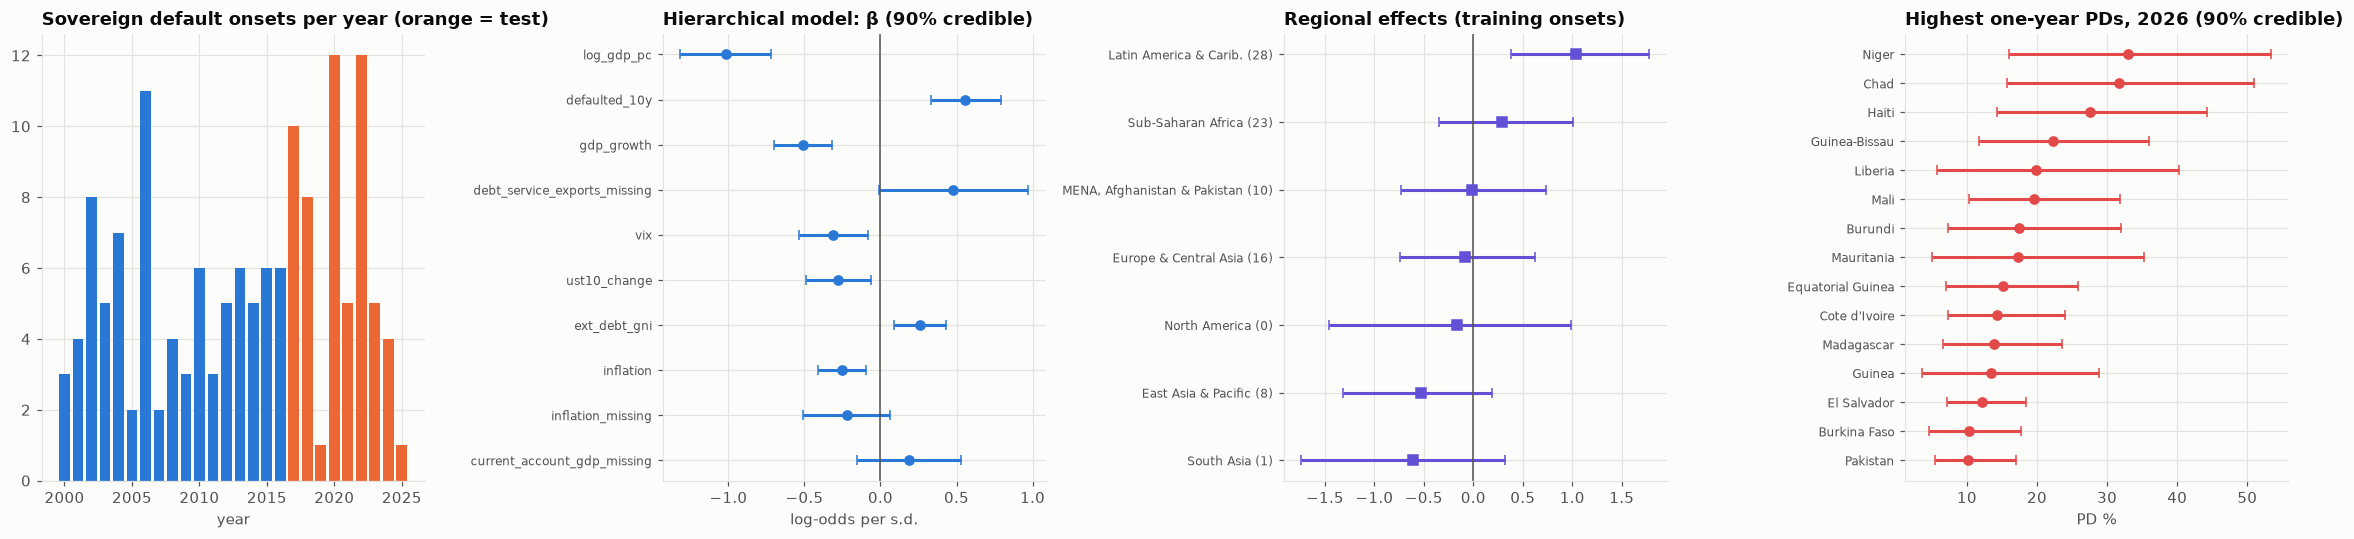

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(21, 5))
ax = axes[0]
ev = risk.groupby("event_year")["y"].sum()
ax.bar(
    ev.index,
    ev.values,
    color=[
        PALETTE[1] if y_ > TRAIN_LAST_EVENT_YEAR else PALETTE[0]
        for y_ in ev.index
    ],
)
ax.set_title("Sovereign default onsets per year (orange = test)")
ax.set_xlabel("year")
ax = axes[1]
cf = coef.head(10).iloc[::-1]
ax.errorbar(
    cf["posterior mean β"],
    range(len(cf)),
    xerr=[
        cf["posterior mean β"] - cf["90% low"],
        cf["90% high"] - cf["posterior mean β"],
    ],
    fmt="o",
    color=PALETTE[0],
    ecolor=PALETTE[0],
    capsize=3,
)
ax.axvline(0, color=INK_2, lw=1)
ax.set_yticks(range(len(cf)), cf.index, fontsize=8)
ax.set_title("Hierarchical model: β (90% credible)")
ax.set_xlabel("log-odds per s.d.")
ax = axes[2]
re_ = reg_eff.sort_values("regional effect (log-odds)")
ax.errorbar(
    re_["regional effect (log-odds)"],
    range(len(re_)),
    xerr=[
        re_["regional effect (log-odds)"] - re_["90% low"],
        re_["90% high"] - re_["regional effect (log-odds)"],
    ],
    fmt="s",
    color=PALETTE[6],
    capsize=3,
)
short = lambda r: r.replace(
    "Middle East, North Africa, Afghanistan & Pakistan",
    "MENA, Afghanistan & Pakistan",
).replace("Latin America & Caribbean", "Latin America & Carib.")
ax.axvline(0, color=INK_2, lw=1)
ax.set_yticks(
    range(len(re_)),
    [f"{short(r)} ({n})" for r, n in zip(re_.index, re_["train onsets"])],
    fontsize=8,
)
ax.set_title("Regional effects (training onsets)")
ax = axes[3]
t15 = top.head(15).iloc[::-1]
ax.errorbar(
    t15["PD %"],
    range(len(t15)),
    xerr=[t15["PD %"] - t15["PD 5%"], t15["PD 95%"] - t15["PD %"]],
    fmt="o",
    color=PALETTE[7],
    capsize=3,
)
ax.set_yticks(range(len(t15)), t15.index, fontsize=8)
ax.set_xlabel("PD %")
ax.set_title("Highest one-year PDs, 2026 (90% credible)")
plt.tight_layout()
save_fig(fig, "01_onsets_drivers_regions_pds")
plt.show()

## 7. Reading the results and limitations

144 default onsets among 200 countries, 1999–2025 (an onset rate of 3.6% per country-year). Training uses onsets in 2000–2016 (86), testing 2017–2025 (58):

**Fundamentals rank sovereigns reasonably well out of time.** On 2017–2025 the hierarchical Bayesian model reaches an AUC of **0.79**, the pooled logit 0.78 and LightGBM 0.81. All three have Brier scores of 0.035, and the riskiest 10% of country-years contain 34–38% of the onsets. The Bayesian model's average PD (3.4%) is closest to the realised onset rate (3.8%); LightGBM's (2.7%) is the most under-predicted.

The test window includes the well-known cases (Lebanon, Sri Lanka, Ghana, Ukraine, Ethiopia) and the 2020 wave of 12 onsets, which came from a shock no annual model sees a year ahead; that wave is one reason only about a third of onsets fall in the top decile.

**The drivers are the classic ones.** Income per head is the strongest protection (β −1.0 per standard deviation, 90% credible interval −1.3 to −0.7). A default in the past ten years is the strongest risk factor (+0.56): serial default is real. Growth protects (−0.51) and external debt to GNI hurts (+0.26).

Missing debt-service statistics are themselves a warning sign (+0.47, with 95% posterior probability of a positive effect), typical of countries with weak data.

**Some signs need care.** Higher VIX and rising U.S. yields come out *protective* (−0.31, −0.28). The global factors are common to every country in a year, so with 26 years they mostly capture timing. For example, the 2008 VIX spike was followed by few onsets in 2009 thanks to the IMF and G20 response.

Inflation is also negative, because countries with very high inflation are often already in default and outside the risk set. These are effects that a validator would not accept as causal; for stress testing, global shocks should be imposed through scenarios rather than these coefficients.

**Partial pooling does what it should.** The regional effect for Latin America is clearly positive (+1.04 log-odds, 90% CI +0.39 to +1.78; 28 training onsets, 6.4% raw onset rate). Sub-Saharan Africa is +0.29 once income and debt are controlled. Regions with few events are pulled toward zero with wide intervals: South Asia (1 onset) −0.61 (−1.74 to +0.33), North America (none) −0.17 (−1.46 to +0.99).

A separate model per region would have given South Asia and North America unusable estimates.

**2026 PDs come with honest uncertainty.** Of 156 sovereigns not in default, the median one-year PD is 1.6%. The highest are Niger (33%, 90% CI 16–53%), Chad (32%), Haiti (28%), Guinea-Bissau (22%) and Mali (20%). In Latin America: El Salvador 12% (7–18%), Belize and Ecuador 10%, Barbados and Jamaica 9%, Brazil 6.3%, Argentina 5.2%, Mexico 2.5%, **Colombia 2.2% (1.3–3.5%)**.

The intervals are what a limits or pricing committee needs: Liberia's 20% could be 6% or 40%.

**Low-default segment.** High-income sovereigns in Europe, North America and East Asia show 9 onsets in 1,420 country-years (0.63%). The list is a reminder of how broad the BoC–BoE definition is: Bulgaria 2001, Slovenia 2002, Greece 2012/2015/2018, Cyprus, Ireland and Portugal 2013, and Russia 2022. Several of these were debt operations most investors would not call defaults.

Their average PD from the hierarchical model today is 0.52%. The Pluto–Tasche most prudent estimate is 1.0% at 90% confidence and 1.3% at 99%. For a portfolio with truly no defaults, Pluto–Tasche would be the only data-based anchor; here it gives a prudent ceiling about twice the model's estimate.

**Limitations**

- The default definition (debt in default ≥ 1% of GDP) counts arrears to official creditors and domestic arrears, which differs from rating-agency definitions and inflates onsets in small low-income countries.
- Countries absent from the BoC–BoE database are treated as never in default; WDI covariates are annual, revised, and missing for some countries (external debt is not compiled for high-income economies).
- Onsets are treated as independent given the covariates; contagion and common shocks would widen the tails of any portfolio loss distribution built on these PDs.

In [10]:
oot.to_csv(OUT_DIR / "out_of_time_evaluation.csv")
coef.to_csv(OUT_DIR / "hierarchical_coefficients.csv")
reg_eff.to_csv(OUT_DIR / "regional_effects.csv")
top.to_csv(OUT_DIR / "sovereign_pd_2026.csv")
low_default.to_csv(OUT_DIR / "low_default_bounds.csv")
print(
    "Outputs written:", ", ".join(sorted(p_.name for p_ in OUT_DIR.iterdir()))
)

Outputs written: 01_onsets_drivers_regions_pds.png, hierarchical_coefficients.csv, low_default_bounds.csv, out_of_time_evaluation.csv, regional_effects.csv, sovereign_pd_2026.csv


## References

### Finance and regulation

- Pluto, K., & Tasche, D. (2005). Estimating probabilities of default for low default portfolios. *Risk, 18*(8), 76–82. https://arxiv.org/abs/cond-mat/0411699
- Manasse, P., & Roubini, N. (2009). "Rules of thumb" for sovereign debt crises. *Journal of International Economics, 78*(2), 192–205. https://doi.org/10.1016/j.jinteco.2008.12.002
- Reinhart, C. M., & Rogoff, K. S. (2009). *This time is different: Eight centuries of financial folly*. Princeton University Press. https://doi.org/10.1515/9781400831722
- Kraay, A., & Nehru, V. (2006). When is external debt sustainable? *The World Bank Economic Review, 20*(3), 341–365. https://doi.org/10.1093/wber/lhl006
- Basel Committee on Banking Supervision. (2005). *Validation of low-default portfolios in the Basel II framework* (Basel Committee Newsletter No. 6). Bank for International Settlements. https://www.bis.org/publ/bcbs_nl6.htm

### Machine learning and deep learning

- Gelman, A., & Hill, J. (2007). *Data analysis using regression and multilevel/hierarchical models*. Cambridge University Press. https://doi.org/10.1017/CBO9780511790942
- Hoffman, M. D., & Gelman, A. (2014). The No-U-Turn sampler: Adaptively setting path lengths in Hamiltonian Monte Carlo. *Journal of Machine Learning Research, 15*, 1593–1623. https://jmlr.org/papers/v15/hoffman14a.html
- Abril-Pla, O., Andreani, V., Carroll, C., Dong, L., Fonnesbeck, C. J., Kochurov, M., … Zinkov, R. (2023). PyMC: A modern, and comprehensive probabilistic programming framework in Python. *PeerJ Computer Science, 9*, e1516. https://doi.org/10.7717/peerj-cs.1516
- Betancourt, M., & Girolami, M. (2015). Hamiltonian Monte Carlo for hierarchical models. In *Current trends in Bayesian methodology with applications*. CRC Press. https://arxiv.org/abs/1312.0906